In [ ]:
#próbka po plazmie tlenowo-argonowej 0,2,4,6,8 s

from funkcje.Lorentz2Raman import *
ustaw_styl_wykresow()
#komentarz

#kolory
colors = ["#808080","#FB7845", "#DB3688","#85154D","#260109"]

In [ ]:
#import wszystkich mapek (i pojedynczych widm dla t=8s) dla próbki 1

BASE = Path().resolve()
sciezka = BASE / "analiza" / "próbka1" / "dane_pomiarowe"

rs_PL_0s, I_PL_0s = importMap(sciezka/"WSe2_mapa_PL_1_0s.txt")
rs_PL_2s, I_PL_2s = importMap(sciezka/"WSe2_mapa_PL_1_2s.txt")
rs_PL_4s, I_PL_4s = importMap(sciezka/"WSe2_mapa_PL_1_4s.txt")
rs_PL_6s, I_PL_6s = importMap(sciezka/"WSe2_mapa_PL_1_6s.txt")

rs_Raman_0s, I_Raman_0s = importMap(sciezka/"WSe2_mapa_Raman_1_0.txt")
rs_Raman_2s, I_Raman_2s = importMap(sciezka/"WSe2_mapa_Raman_1_2s.txt")
rs_Raman_4s, I_Raman_4s = importMap(sciezka/"WSe2_mapa_Raman_1_4s.txt")
rs_Raman_6s, I_Raman_6s = importMap(sciezka/"WSe2_mapa_Raman_1_6s.txt")

rs_PL_8s, I_PL_8s       = importSpectrum(sciezka/"WSe2_PL_1_8s.txt")
rs_Raman_8s, I_Raman_8s = importSpectrum(sciezka/"WSe2_Raman_1_8s.txt")

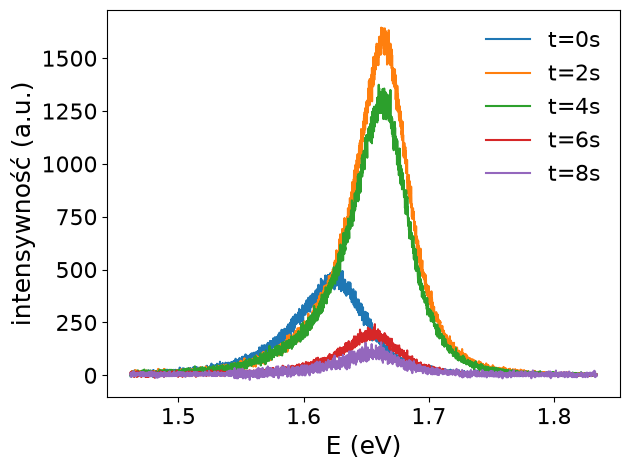

In [ ]:
#testowe pojedyncze widma PL, żebym wiedziała co dopasować 

plt.plot(rs_PL_0s[123], I_PL_0s[123],label="t=0s")
plt.plot(rs_PL_2s[31], I_PL_2s[21],label="t=2s")
plt.plot(rs_PL_4s[123], I_PL_4s[123],label="t=4s")
plt.plot(rs_PL_6s[123], I_PL_6s[123],label="t=6s")
plt.plot(rs_PL_8s,I_PL_8s,label="t=8s")
plt.xlabel(r"E (eV)")
plt.ylabel("intensywność (a.u.)")
plt.legend()


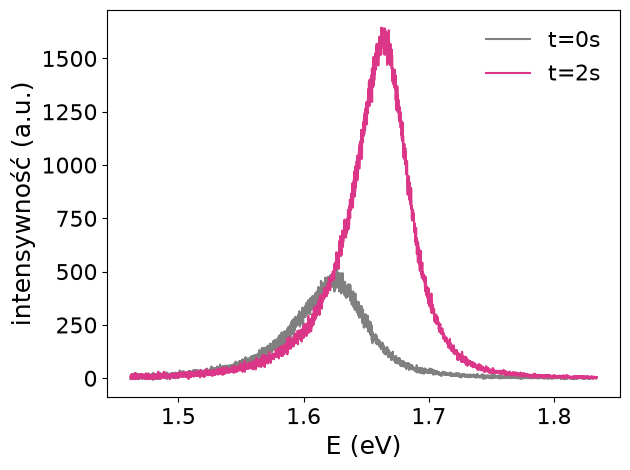

In [ ]:
#testowe pojedyncze widma PL dla 0s i 2s do sekcji "dobór parametrów defektowania"

plt.plot(rs_PL_0s[123], I_PL_0s[123],label="t=0s",color=colors[0])
plt.plot(rs_PL_2s[31], I_PL_2s[21],label="t=2s",color=colors[2])

plt.xlabel(r"E (eV)")
plt.ylabel("intensywność (a.u.)")
plt.legend()
BASE = Path().resolve()
sciezka = BASE / "analiza" / "próbka1" / "wykresy"
plt.savefig(sciezka / "PL2s.png")

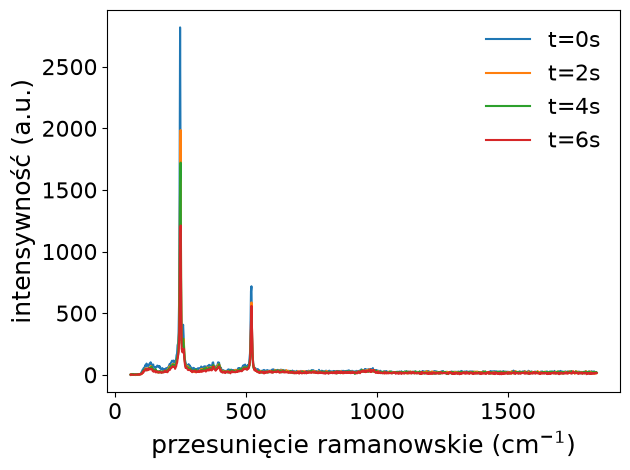

In [ ]:
# testowe pojedyncze widma ramana, żebym wiedziała co dopasować 

plt.plot(rs_Raman_0s[123], I_Raman_0s[123],label="t=0s")
plt.plot(rs_Raman_2s[123], I_Raman_2s[123],label="t=2s")
plt.plot(rs_Raman_4s[123], I_Raman_4s[123],label="t=4s")
plt.plot(rs_Raman_6s[123], I_Raman_6s[123],label="t=6s")
plt.xlabel(r"przesunięcie ramanowskie (cm$^{-1}$)")
plt.ylabel("intensywność (a.u.)")
plt.legend()

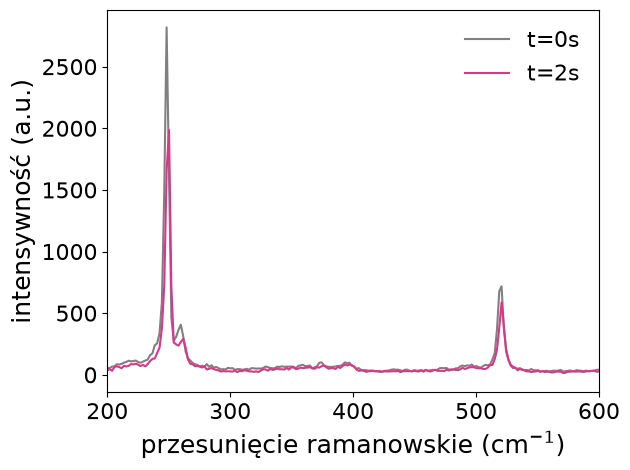

In [ ]:
#pojedyncze widma dla 0s i 2s do sekcji "dobór parametrów defektowania"

plt.plot(rs_Raman_0s[123], I_Raman_0s[123],label="t=0s",color=colors[0])
plt.plot(rs_Raman_2s[123], I_Raman_2s[123],label="t=2s",color=colors[2])
plt.xlabel(r"przesunięcie ramanowskie (cm$^{-1}$)")
plt.ylabel("intensywność (a.u.)")
plt.legend()
plt.xlim(200,600)
plt.savefig(sciezka/'Raman2s.png')

In [ ]:
#dopasowanie piku PL

centers_PL_0s, fwhms_PL_0s, intensities_PL_0s = lorentz2map(rs_PL_0s, I_PL_0s, xmin=1.5, xmax=1.7)
centers_PL_2s, fwhms_PL_2s, intensities_PL_2s = lorentz2map(rs_PL_2s, I_PL_2s, xmin=1.55, xmax=1.75)
centers_PL_4s, fwhms_PL_4s, intensities_PL_4s = lorentz2map(rs_PL_4s, I_PL_4s, xmin=1.55, xmax=1.75)
centers_PL_6s, fwhms_PL_6s, intensities_PL_6s = lorentz2map(rs_PL_6s, I_PL_6s, xmin=1.55, xmax=1.75)

centers_PL_8s, fwhms_PL_8s, intensities_PL_8s = fitLorentz((rs_PL_8s, I_PL_8s, 1.5, 1.75))

In [ ]:
#usunięcie punktów mocno odstających - krawędzi monowarswty/samego podłoża
maska_PL_0s=(fwhms_PL_0s>=0.05) &(fwhms_PL_0s<=0.071)
fwhms_PL_0s=fwhms_PL_0s[maska_PL_0s]
centers_PL_0s=centers_PL_0s[maska_PL_0s]
intensities_PL_0s=intensities_PL_0s[maska_PL_0s]
maska_PL_0s=(intensities_PL_0s>=0) &(intensities_PL_0s<=1000)
fwhms_PL_0s=fwhms_PL_0s[maska_PL_0s]
centers_PL_0s=centers_PL_0s[maska_PL_0s]
intensities_PL_0s=intensities_PL_0s[maska_PL_0s]


maska_PL_2s=(fwhms_PL_2s>=0.04) &(fwhms_PL_2s<=0.055)
fwhms_PL_2s=fwhms_PL_2s[maska_PL_2s]
centers_PL_2s=centers_PL_2s[maska_PL_2s]
intensities_PL_2s=intensities_PL_2s[maska_PL_2s]
maska_PL_2s=(intensities_PL_2s>=1000) &(intensities_PL_2s<=2500)
fwhms_PL_2s=fwhms_PL_2s[maska_PL_2s]
centers_PL_2s=centers_PL_2s[maska_PL_2s]
intensities_PL_2s=intensities_PL_2s[maska_PL_2s]




maska_PL_4s=(fwhms_PL_4s>=0.04) &(fwhms_PL_4s<=0.055)
fwhms_PL_4s=fwhms_PL_4s[maska_PL_4s]
centers_PL_4s=centers_PL_4s[maska_PL_4s]
intensities_PL_4s=intensities_PL_4s[maska_PL_4s]
maska_PL_4s=(intensities_PL_4s>=500) &(intensities_PL_4s<=1700)
fwhms_PL_4s=fwhms_PL_4s[maska_PL_4s]
centers_PL_4s=centers_PL_4s[maska_PL_4s]
intensities_PL_4s=intensities_PL_4s[maska_PL_4s]



maska_PL_6s=(fwhms_PL_6s>=0.04) &(fwhms_PL_6s<=0.06)
fwhms_PL_6s=fwhms_PL_6s[maska_PL_6s]
centers_PL_6s=centers_PL_6s[maska_PL_6s]
intensities_PL_6s=intensities_PL_6s[maska_PL_6s]
maska_PL_6s=(intensities_PL_6s>=0) &(intensities_PL_6s<=500)
fwhms_PL_6s=fwhms_PL_6s[maska_PL_6s]
centers_PL_6s=centers_PL_6s[maska_PL_6s]
intensities_PL_6s=intensities_PL_6s[maska_PL_6s]






In [ ]:
#dopasowanie piku E+A

centers_Raman_EA_0s, fwhms_Raman_EA_0s, intensities_Raman_EA_0s = lorentz2map(rs_Raman_0s, I_Raman_0s, xmin=240, xmax=255)
centers_Raman_EA_2s, fwhms_Raman_EA_2s, intensities_Raman_EA_2s = lorentz2map(rs_Raman_2s, I_Raman_2s, xmin=240, xmax=255)
centers_Raman_EA_4s, fwhms_Raman_EA_4s, intensities_Raman_EA_4s = lorentz2map(rs_Raman_4s, I_Raman_4s, xmin=240, xmax=255)
centers_Raman_EA_6s, fwhms_Raman_EA_6s, intensities_Raman_EA_6s = lorentz2map(rs_Raman_6s, I_Raman_6s,xmin=240, xmax=255)

centers_Raman_EA_8s, fwhms_Raman_EA_8s, intensities_Raman_EA_8s =fitLorentz((rs_Raman_8s, I_Raman_8s,240,255))


In [ ]:
#usunięcie punktów mocno odstających - krawędzi monowarswty/samego podłoża
maska_Raman_EA_0s=(fwhms_Raman_EA_0s>=0) &(fwhms_Raman_EA_0s<=20)
fwhms_Raman_EA_0s=fwhms_Raman_EA_0s[maska_Raman_EA_0s]
centers_Raman_EA_0s=centers_Raman_EA_0s[maska_Raman_EA_0s]
intensities_Raman_EA_0s=intensities_Raman_EA_0s[maska_Raman_EA_0s]
maska_Raman_EA_0s=(intensities_Raman_EA_0s>=2500) &(intensities_Raman_EA_0s<=3250)
fwhms_Raman_EA_0s=fwhms_Raman_EA_0s[maska_Raman_EA_0s]
centers_Raman_EA_0s=centers_Raman_EA_0s[maska_Raman_EA_0s]
intensities_Raman_EA_0s=intensities_Raman_EA_0s[maska_Raman_EA_0s]

maska_Raman_EA_2s=(fwhms_Raman_EA_2s>=0) &(fwhms_Raman_EA_2s<=20)
fwhms_Raman_EA_2s=fwhms_Raman_EA_2s[maska_Raman_EA_2s]
centers_Raman_EA_2s=centers_Raman_EA_2s[maska_Raman_EA_2s]
intensities_Raman_EA_2s=intensities_Raman_EA_2s[maska_Raman_EA_2s]
maska_Raman_EA_2s=(intensities_Raman_EA_2s>=1900) &(intensities_Raman_EA_2s<=2500)
fwhms_Raman_EA_2s=fwhms_Raman_EA_2s[maska_Raman_EA_2s]
centers_Raman_EA_2s=centers_Raman_EA_2s[maska_Raman_EA_2s]
intensities_Raman_EA_2s=intensities_Raman_EA_2s[maska_Raman_EA_2s]



maska_Raman_EA_4s=(fwhms_Raman_EA_4s>=0) &(fwhms_Raman_EA_4s<=20)
fwhms_Raman_EA_4s=fwhms_Raman_EA_4s[maska_Raman_EA_4s]
centers_Raman_EA_4s=centers_Raman_EA_4s[maska_Raman_EA_4s]
intensities_Raman_EA_4s=intensities_Raman_EA_4s[maska_Raman_EA_4s]
maska_Raman_EA_4s=(intensities_Raman_EA_4s>=1500) &(intensities_Raman_EA_4s<=2000)
fwhms_Raman_EA_4s=fwhms_Raman_EA_4s[maska_Raman_EA_4s]
centers_Raman_EA_4s=centers_Raman_EA_4s[maska_Raman_EA_4s]
intensities_Raman_EA_4s=intensities_Raman_EA_4s[maska_Raman_EA_4s]


maska_Raman_EA_6s=(fwhms_Raman_EA_6s>=0) &(fwhms_Raman_EA_6s<=20)
fwhms_Raman_EA_6s=fwhms_Raman_EA_6s[maska_Raman_EA_6s]
centers_Raman_EA_6s=centers_Raman_EA_6s[maska_Raman_EA_6s]
intensities_Raman_EA_6s=intensities_Raman_EA_6s[maska_Raman_EA_6s]
maska_Raman_EA_6s=(intensities_Raman_EA_6s>=1250) &(intensities_Raman_EA_6s<=1750)
fwhms_Raman_EA_6s=fwhms_Raman_EA_6s[maska_Raman_EA_6s]
centers_Raman_EA_6s=centers_Raman_EA_6s[maska_Raman_EA_6s]
intensities_Raman_EA_6s=intensities_Raman_EA_6s[maska_Raman_EA_6s]


In [ ]:
#dopasowanie piku 2LA(M)

centers_Raman_LA_0s, fwhms_Raman_LA_0s, intensities_Raman_LA_0s = lorentz2map(rs_Raman_0s, I_Raman_0s, xmin=255, xmax=265)
centers_Raman_LA_2s, fwhms_Raman_LA_2s, intensities_Raman_LA_2s = lorentz2map(rs_Raman_2s, I_Raman_2s, xmin=255, xmax=265)
centers_Raman_LA_4s, fwhms_Raman_LA_4s, intensities_Raman_LA_4s = lorentz2map(rs_Raman_4s, I_Raman_4s, xmin=255, xmax=265)
centers_Raman_LA_6s, fwhms_Raman_LA_6s, intensities_Raman_LA_6s = lorentz2map(rs_Raman_6s, I_Raman_6s,xmin=255, xmax=265)

centers_Raman_LA_8s, fwhms_Raman_LA_8s, intensities_Raman_LA_8s =fitLorentz((rs_Raman_8s, I_Raman_8s,255,265))

In [ ]:
maska_Raman_LA_0s=(centers_Raman_LA_0s>=258) &(centers_Raman_LA_0s<=260)
fwhms_Raman_LA_0s=fwhms_Raman_LA_0s[maska_Raman_LA_0s]
centers_Raman_LA_0s=centers_Raman_LA_0s[maska_Raman_LA_0s]
intensities_Raman_LA_0s=intensities_Raman_LA_0s[maska_Raman_LA_0s]
maska_Raman_LA_0s=(intensities_Raman_LA_0s>=350) &(intensities_Raman_LA_0s<=450)
fwhms_Raman_LA_0s=fwhms_Raman_LA_0s[maska_Raman_LA_0s]
centers_Raman_LA_0s=centers_Raman_LA_0s[maska_Raman_LA_0s]
intensities_Raman_LA_0s=intensities_Raman_LA_0s[maska_Raman_LA_0s]



maska_Raman_LA_2s=(centers_Raman_LA_2s>=259) &(centers_Raman_LA_2s<=261.2)
fwhms_Raman_LA_2s=fwhms_Raman_LA_2s[maska_Raman_LA_2s]
centers_Raman_LA_2s=centers_Raman_LA_2s[maska_Raman_LA_2s]
intensities_Raman_LA_2s=intensities_Raman_LA_2s[maska_Raman_LA_2s]
maska_Raman_LA_2s=(intensities_Raman_LA_2s>=240) &(intensities_Raman_LA_2s<=350)
fwhms_Raman_LA_2s=fwhms_Raman_LA_2s[maska_Raman_LA_2s]
centers_Raman_LA_2s=centers_Raman_LA_2s[maska_Raman_LA_2s]
intensities_Raman_LA_2s=intensities_Raman_LA_2s[maska_Raman_LA_2s]


maska_Raman_LA_4s=(centers_Raman_LA_4s>=258) &(centers_Raman_LA_4s<=265)
fwhms_Raman_LA_4s=fwhms_Raman_LA_4s[maska_Raman_LA_4s]
centers_Raman_LA_4s=centers_Raman_LA_4s[maska_Raman_LA_4s]
intensities_Raman_LA_4s=intensities_Raman_LA_4s[maska_Raman_LA_4s]
maska_Raman_LA_4s=(intensities_Raman_LA_4s>=200) &(intensities_Raman_LA_4s<=300)
fwhms_Raman_LA_4s=fwhms_Raman_LA_4s[maska_Raman_LA_4s]
centers_Raman_LA_4s=centers_Raman_LA_4s[maska_Raman_LA_4s]
intensities_Raman_LA_4s=intensities_Raman_LA_4s[maska_Raman_LA_4s]


maska_Raman_LA_6s=(centers_Raman_LA_6s>=258) &(centers_Raman_LA_6s<=265)
fwhms_Raman_LA_6s=fwhms_Raman_LA_6s[maska_Raman_LA_6s]
centers_Raman_LA_6s=centers_Raman_LA_6s[maska_Raman_LA_6s]
intensities_Raman_LA_6s=intensities_Raman_LA_6s[maska_Raman_LA_6s]
maska_Raman_LA_6s=(intensities_Raman_LA_6s>=200) &(intensities_Raman_LA_6s<=260)
fwhms_Raman_LA_6s=fwhms_Raman_LA_6s[maska_Raman_LA_6s]
centers_Raman_LA_6s=centers_Raman_LA_6s[maska_Raman_LA_6s]
intensities_Raman_LA_6s=intensities_Raman_LA_6s[maska_Raman_LA_6s]

In [ ]:
plt.rcParams.update(
        {
            "axes.labelsize":18,
            "xtick.labelsize":16,
            "ytick.labelsize":16,
            "legend.fontsize":16,
            "figure.autolayout":True,
        }
    )

In [ ]:
#średnie pozycji PL na podstawie rozkładu normalnego
mu_centers_PL_0s, sigma_centers_PL_0s = norm.fit(centers_PL_0s)
print(f"{mu_centers_PL_0s} ± {sigma_centers_PL_0s}")
x_centers_PL_0s,y_centers_PL_0s=gauss(mu_centers_PL_0s,sigma_centers_PL_0s)

mu_centers_PL_2s, sigma_centers_PL_2s = norm.fit(centers_PL_2s)
print(f"{mu_centers_PL_2s} ± {sigma_centers_PL_2s}")
x_centers_PL_2s,y_centers_PL_2s=gauss(mu_centers_PL_2s,sigma_centers_PL_2s)

mu_centers_PL_4s, sigma_centers_PL_4s = norm.fit(centers_PL_4s)
print(f"{mu_centers_PL_4s} ± {sigma_centers_PL_4s}")
x_centers_PL_4s,y_centers_PL_4s=gauss(mu_centers_PL_4s,sigma_centers_PL_4s)


mu_centers_PL_6s, sigma_centers_PL_6s = norm.fit(centers_PL_6s)
print(f"{mu_centers_PL_6s} ± {sigma_centers_PL_6s}")
x_centers_PL_6s,y_centers_PL_6s=gauss(mu_centers_PL_6s,sigma_centers_PL_6s)

#print(centers_PL_8s)
mu_centers_PL_8s, sigma_centers_PL_8s = norm.fit(centers_PL_8s)
#tylko jedno widmo dla 8s więc nie ma sensu liczyć niepewności standardowej średniej
print(f"{mu_centers_PL_8s} ± {sigma_centers_PL_8s}")

mu_centers_PL=[mu_centers_PL_0s,mu_centers_PL_2s,mu_centers_PL_4s,mu_centers_PL_6s,centers_PL_8s]
u_centers_PL=[sigma_centers_PL_0s,sigma_centers_PL_2s,sigma_centers_PL_4s,sigma_centers_PL_6s,0]

1.6292199218983563 ± 0.006850802904415871
1.6612390728385116 ± 0.0019398655496707798
1.6598417510968675 ± 0.0021098351453500775
1.6535328139094845 ± 0.0028883622737717668
1.6531518683287856 ± 0.0


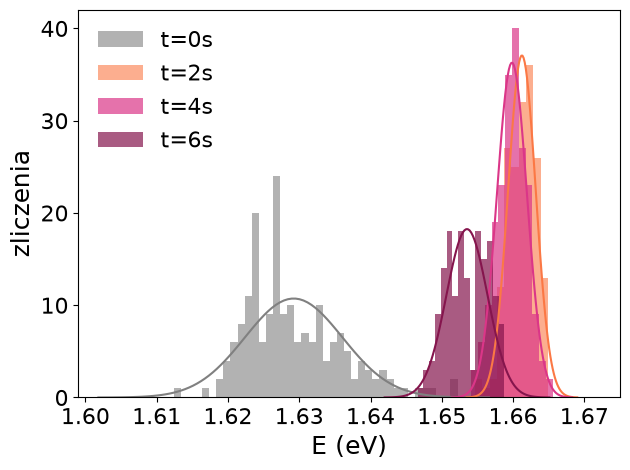

In [ ]:
#histogramy pozycji piku PL
szerokosc_binu_centers_PL_0s = (np.max(centers_PL_0s)-np.min(centers_PL_0s))/40
liczba_probek_centers_PL_0s = len(centers_PL_0s)
y_centers_PL_0s_ = y_centers_PL_0s*liczba_probek_centers_PL_0s*szerokosc_binu_centers_PL_0s


szerokosc_binu_centers_PL_2s = (np.max(centers_PL_2s)-np.min(centers_PL_2s))/10
liczba_probek_centers_PL_2s = len(centers_PL_2s)
y_centers_PL_2s_=y_centers_PL_2s*liczba_probek_centers_PL_2s*szerokosc_binu_centers_PL_2s

szerokosc_binu_centers_PL_4s=(np.max(centers_PL_4s)-np.min(centers_PL_4s))/12
liczba_probek_centers_PL_4s=len(centers_PL_4s)
y_centers_PL_4s_=y_centers_PL_4s*liczba_probek_centers_PL_4s*szerokosc_binu_centers_PL_4s


szerokosc_binu_centers_PL_6s=(np.max(centers_PL_6s)-np.min(centers_PL_6s))/15
liczba_probek_centers_PL_6s=len(centers_PL_6s)
y_centers_PL_6s_=y_centers_PL_6s*liczba_probek_centers_PL_6s*szerokosc_binu_centers_PL_6s

plt.hist(centers_PL_0s, bins=40, label="t=0s", alpha=0.6, color=colors[0])
plt.plot(x_centers_PL_0s,y_centers_PL_0s_,color=colors[0])

plt.hist(centers_PL_2s, bins=10, label="t=2s", alpha=0.60,color=colors[1])
plt.plot(x_centers_PL_2s,y_centers_PL_2s_,color=colors[1])

plt.hist(centers_PL_4s, bins=12, label="t=4s", alpha=0.70,color=colors[2])
plt.plot(x_centers_PL_4s,y_centers_PL_4s_,color=colors[2])

plt.hist(centers_PL_6s, bins=15, label="t=6s",alpha=0.70,color=colors[3])
plt.plot(x_centers_PL_6s,y_centers_PL_6s_,color=colors[3])

plt.xlabel(r"E (eV)")
plt.ylabel("zliczenia")
plt.xlim(1.599,1.675)
plt.legend()

plt.savefig(sciezka/'histogram_pozycji_PL.png')

In [ ]:
#średnie intensywności PL na podstawie rozkładu normalnego
mu_intensities_PL_0s, sigma_intensities_PL_0s = norm.fit(intensities_PL_0s)
print(f"{mu_intensities_PL_0s} ± {sigma_intensities_PL_0s}")
x_intensities_PL_0s,y_intensities_PL_0s=gauss(mu_intensities_PL_0s,sigma_intensities_PL_0s)


mu_intensities_PL_2s, sigma_intensities_PL_2s = norm.fit(intensities_PL_2s)
print(f"{mu_intensities_PL_2s} ± {sigma_intensities_PL_2s}")
x_intensities_PL_2s,y_intensities_PL_2s=gauss(mu_intensities_PL_2s,sigma_intensities_PL_2s)


mu_intensities_PL_4s, sigma_intensities_PL_4s = norm.fit(intensities_PL_4s)
print(f"{mu_intensities_PL_4s} ± {sigma_intensities_PL_4s}")
x_intensities_PL_4s,y_intensities_PL_4s=gauss(mu_intensities_PL_4s,sigma_intensities_PL_4s)


mu_intensities_PL_6s, sigma_intensities_PL_6s = norm.fit(intensities_PL_6s)
print(f"{mu_intensities_PL_6s} ± {sigma_intensities_PL_6s}")
x_intensities_PL_6s,y_intensities_PL_6s=gauss(mu_intensities_PL_6s,sigma_intensities_PL_6s)



mu_intensities_PL_8s, sigma_intensities_PL_8s = norm.fit(intensities_PL_8s)
print(f"{mu_intensities_PL_8s} ± {sigma_intensities_PL_8s}")

mu_intensities_PL=[mu_intensities_PL_0s,mu_intensities_PL_2s,mu_intensities_PL_4s,mu_intensities_PL_6s,mu_intensities_PL_8s]
u_intensities_PL=[sigma_intensities_PL_0s,sigma_intensities_PL_2s,sigma_intensities_PL_4s,sigma_intensities_PL_6s,sigma_intensities_PL_8s]

607.5382263960663 ± 141.24184963710422
1697.5046532817023 ± 316.8067610585412
1197.0623381517705 ± 273.08837447058374
278.80907255958977 ± 70.56475672424786
105.00322778302734 ± 0.0


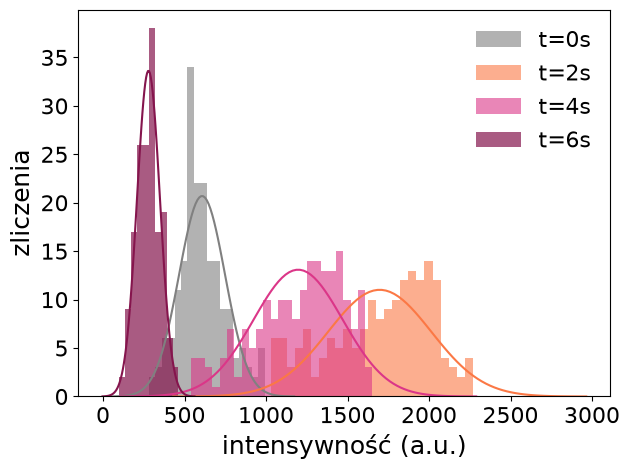

In [ ]:
#histogramy intensywności piku PL
szerokosc_binu_intensities_PL_0s = (np.max(intensities_PL_0s)-np.min(intensities_PL_0s))/18
liczba_probek_intensities_PL_0s = len(intensities_PL_0s)
y_intensities_PL_0s_ = y_intensities_PL_0s*liczba_probek_intensities_PL_0s*szerokosc_binu_intensities_PL_0s


szerokosc_binu_intensities_PL_2s = (np.max(intensities_PL_2s)-np.min(intensities_PL_2s))/25
liczba_probek_intensities_PL_2s = len(intensities_PL_2s)
y_intensities_PL_2s_ = y_intensities_PL_2s*liczba_probek_intensities_PL_2s*szerokosc_binu_intensities_PL_2s

szerokosc_binu_intensities_PL_4s = (np.max(intensities_PL_4s)-np.min(intensities_PL_4s))/25
liczba_probek_intensities_PL_4s = len(intensities_PL_4s)
y_intensities_PL_4s_ = y_intensities_PL_4s*liczba_probek_intensities_PL_4s*szerokosc_binu_intensities_PL_4s

szerokosc_binu_intensities_PL_6s = (np.max(intensities_PL_6s)-np.min(intensities_PL_6s))/10
liczba_probek_intensities_PL_6s = len(intensities_PL_6s)
y_intensities_PL_6s_ = y_intensities_PL_6s*liczba_probek_intensities_PL_6s*szerokosc_binu_intensities_PL_6s




plt.hist(intensities_PL_0s, bins=18, label="t=0s",alpha=0.6, color=colors[0])
plt.plot(x_intensities_PL_0s,y_intensities_PL_0s_,color=colors[0])
plt.hist(intensities_PL_2s, bins=25, label="t=2s", alpha=0.6,color=colors[1])
plt.plot(x_intensities_PL_2s,y_intensities_PL_2s_,color=colors[1])
plt.hist(intensities_PL_4s, bins=25, label="t=4s",alpha=0.60,color=colors[2])
plt.plot(x_intensities_PL_4s,y_intensities_PL_4s_,color=colors[2])
plt.hist(intensities_PL_6s, bins=10, label="t=6s", alpha=0.70,color=colors[3])
plt.plot(x_intensities_PL_6s,y_intensities_PL_6s_,color=colors[3])
plt.xlabel(r"intensywność (a.u.)")
plt.ylabel("zliczenia")
plt.legend()
plt.savefig(sciezka/'histogram_intensywnosci_PL.png')

In [ ]:
mu_fwhms_PL_0s, sigma_fwhms_PL_0s = norm.fit(fwhms_PL_0s)
print(f"{mu_fwhms_PL_0s} ± {sigma_fwhms_PL_0s}")
x_fwhms_PL_0s,y_fwhms_PL_0s=gauss(mu_fwhms_PL_0s,sigma_fwhms_PL_0s)


mu_fwhms_PL_2s, sigma_fwhms_PL_2s = norm.fit(fwhms_PL_2s)
print(f"{mu_fwhms_PL_2s} ± {sigma_fwhms_PL_2s}")
x_fwhms_PL_2s,y_fwhms_PL_2s=gauss(mu_fwhms_PL_2s,sigma_fwhms_PL_2s)


mu_fwhms_PL_4s, sigma_fwhms_PL_4s = norm.fit(fwhms_PL_4s)
print(f"{mu_fwhms_PL_4s} ± {sigma_fwhms_PL_4s}")
x_fwhms_PL_4s,y_fwhms_PL_4s=gauss(mu_fwhms_PL_4s,sigma_fwhms_PL_4s)


mu_fwhms_PL_6s, sigma_fwhms_PL_6s = norm.fit(fwhms_PL_6s)
print(f"{mu_fwhms_PL_6s} ± {sigma_fwhms_PL_6s}")
x_fwhms_PL_6s,y_fwhms_PL_6s=gauss(mu_fwhms_PL_6s,sigma_fwhms_PL_6s)

mu_fwhms_PL_8s, sigma_fwhms_PL_8s = norm.fit(fwhms_PL_8s)
#tylko jedno widmo dla 8s więc nie ma sensu liczyć niepewności standardowej średniej
print(f"{mu_fwhms_PL_8s} ± {sigma_fwhms_PL_8s}")

mu_fwhms_PL=[mu_fwhms_PL_0s,mu_fwhms_PL_2s,mu_fwhms_PL_4s,mu_fwhms_PL_6s,mu_fwhms_PL_8s]
u_fwhms_PL=[sigma_fwhms_PL_0s,sigma_fwhms_PL_2s,sigma_fwhms_PL_4s,sigma_fwhms_PL_6s,sigma_fwhms_PL_8s]



0.060368906299435664 ± 0.003802439163280561
0.046881605495778314 ± 0.0013321717838099835
0.04894491007526664 ± 0.0016890213231907942
0.05013985971870221 ± 0.002129532526276418
0.0550440907792733 ± 0.0


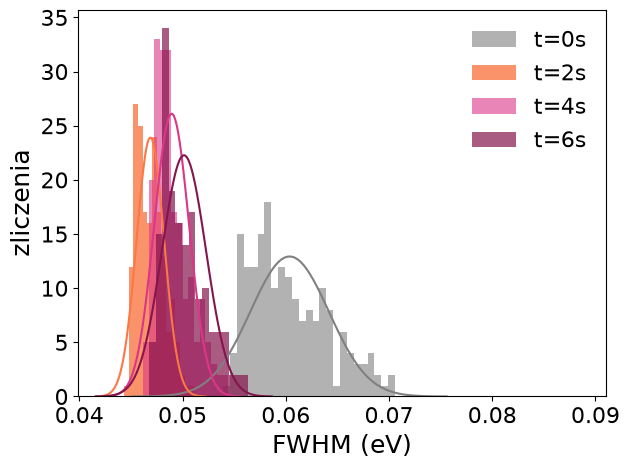

In [ ]:
#histogramy fwhm piku PL
szerokosc_binu_fwhms_PL_0s = (np.max(fwhms_PL_0s)-np.min(fwhms_PL_0s))/25
liczba_probek_fwhms_PL_0s = len(fwhms_PL_0s)
y_fwhms_PL_0s_ = y_fwhms_PL_0s*liczba_probek_fwhms_PL_0s*szerokosc_binu_fwhms_PL_0s

szerokosc_binu_fwhms_PL_2s = (np.max(fwhms_PL_2s)-np.min(fwhms_PL_2s))/15
liczba_probek_fwhms_PL_2s = len(fwhms_PL_2s)
y_fwhms_PL_2s_ = y_fwhms_PL_2s*liczba_probek_fwhms_PL_2s*szerokosc_binu_fwhms_PL_2s

szerokosc_binu_fwhms_PL_4s = (np.max(fwhms_PL_4s)-np.min(fwhms_PL_4s))/15
liczba_probek_fwhms_PL_4s = len(fwhms_PL_4s)
y_fwhms_PL_4s_ = y_fwhms_PL_4s*liczba_probek_fwhms_PL_4s*szerokosc_binu_fwhms_PL_4s

szerokosc_binu_fwhms_PL_6s = (np.max(fwhms_PL_6s)-np.min(fwhms_PL_6s))/15
liczba_probek_fwhms_PL_6s = len(fwhms_PL_0s)
y_fwhms_PL_6s_ = y_fwhms_PL_6s*liczba_probek_fwhms_PL_6s*szerokosc_binu_fwhms_PL_6s



plt.hist(fwhms_PL_0s, bins=25, label="t=0s",alpha=0.6, color=colors[0])
plt.plot(x_fwhms_PL_0s,y_fwhms_PL_0s_,color=colors[0])

plt.hist(fwhms_PL_2s, bins=15, label="t=2s",alpha=0.80,color=colors[1])
plt.plot(x_fwhms_PL_2s,y_fwhms_PL_2s_,color=colors[1])

plt.hist(fwhms_PL_4s, bins=15, label="t=4s",alpha=0.60,color=colors[2])
plt.plot(x_fwhms_PL_4s,y_fwhms_PL_4s_,color=colors[2])

plt.hist(fwhms_PL_6s, bins=15, label="t=6s",alpha=0.70,color=colors[3])
plt.plot(x_fwhms_PL_6s,y_fwhms_PL_6s_,color=colors[3])
plt.xlabel(r"FWHM (eV)")
plt.ylabel("zliczenia")
plt.xlim(0.0399,0.091)
plt.legend()
plt.savefig(sciezka/'histogram_fwhm_PL.png')

In [ ]:
#średnie pozycje pików E i A na podstawie rozkładu normalnego
mu_centers_Raman_EA_0s, sigma_centers_Raman_EA_0s = norm.fit(centers_Raman_EA_0s)
print(f"{mu_centers_Raman_EA_0s} ± {sigma_centers_Raman_EA_0s}")
x_centers_Raman_EA_0s,y_centers_Raman_EA_0s=gauss(mu_centers_Raman_EA_0s,sigma_centers_Raman_EA_0s)

mu_centers_Raman_EA_2s, sigma_centers_Raman_EA_2s = norm.fit(centers_Raman_EA_2s)
print(f"{mu_centers_Raman_EA_2s} ± {sigma_centers_Raman_EA_2s}")
x_centers_Raman_EA_2s,y_centers_Raman_EA_2s=gauss(mu_centers_Raman_EA_2s,sigma_centers_Raman_EA_2s)

mu_centers_Raman_EA_4s, sigma_centers_Raman_EA_4s = norm.fit(centers_Raman_EA_4s)
print(f"{mu_centers_Raman_EA_4s} ± {sigma_centers_Raman_EA_4s}")
x_centers_Raman_EA_4s,y_centers_Raman_EA_4s=gauss(mu_centers_Raman_EA_4s,sigma_centers_Raman_EA_4s)


mu_centers_Raman_EA_6s, sigma_centers_Raman_EA_6s = norm.fit(centers_Raman_EA_6s)
print(f"{mu_centers_Raman_EA_6s} ± {sigma_centers_Raman_EA_6s}")
x_centers_Raman_EA_6s,y_centers_Raman_EA_6s=gauss(mu_centers_Raman_EA_6s,sigma_centers_Raman_EA_6s)

mu_centers_Raman_EA_8s, sigma_centers_Raman_EA_8s = norm.fit(centers_Raman_EA_8s)
print(f"{mu_centers_Raman_EA_8s} ± {sigma_centers_Raman_EA_8s}")

mu_centers_EA=[mu_centers_Raman_EA_0s,mu_centers_Raman_EA_2s,mu_centers_Raman_EA_4s,mu_centers_Raman_EA_6s,mu_centers_Raman_EA_8s]
u_centers_EA=[sigma_centers_Raman_EA_0s,sigma_centers_Raman_EA_2s,sigma_centers_Raman_EA_4s,sigma_centers_Raman_EA_6s,sigma_centers_Raman_EA_8s]

248.43348228870718 ± 0.07720448618956101
249.4800768818746 ± 0.050108896089927045
249.28354402749147 ± 0.056565828641758256
249.43343073221183 ± 0.04909689190276699
249.479244417918 ± 0.0


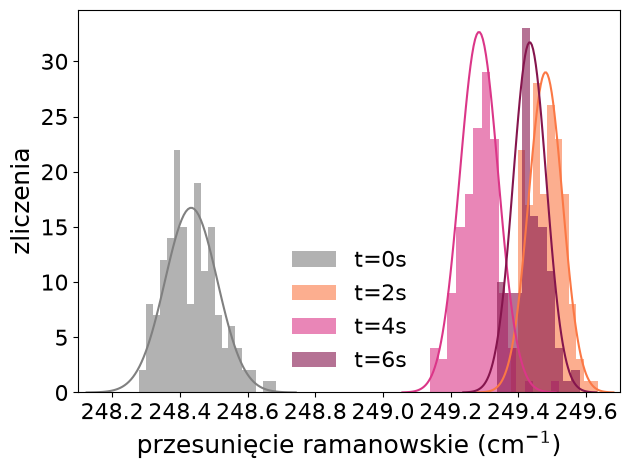

In [ ]:
#histogramy pozycji piku Raman E i A
szerokosc_binu_centers_Raman_EA_0s = (np.max(centers_Raman_EA_0s)-np.min(centers_Raman_EA_0s))/20
liczba_probek_centers_Raman_EA_0s = len(centers_Raman_EA_0s)
y_centers_Raman_EA_0s_ = y_centers_Raman_EA_0s*liczba_probek_centers_Raman_EA_0s*szerokosc_binu_centers_Raman_EA_0s

szerokosc_binu_centers_Raman_EA_2s = (np.max(centers_Raman_EA_2s)-np.min(centers_Raman_EA_2s))/12
liczba_probek_centers_Raman_EA_2s = len(centers_Raman_EA_2s)
y_centers_Raman_EA_2s_ = y_centers_Raman_EA_2s*liczba_probek_centers_Raman_EA_2s*szerokosc_binu_centers_Raman_EA_2s


szerokosc_binu_centers_Raman_EA_4s = (np.max(centers_Raman_EA_2s)-np.min(centers_Raman_EA_4s))/15
liczba_probek_centers_Raman_EA_4s = len(centers_Raman_EA_4s)
y_centers_Raman_EA_4s_ = y_centers_Raman_EA_4s*liczba_probek_centers_Raman_EA_4s*szerokosc_binu_centers_Raman_EA_4s


szerokosc_binu_centers_Raman_EA_6s = (np.max(centers_Raman_EA_6s)-np.min(centers_Raman_EA_6s))/10
liczba_probek_centers_Raman_EA_6s = len(centers_Raman_EA_0s)
y_centers_Raman_EA_6s_ = y_centers_Raman_EA_6s*liczba_probek_centers_Raman_EA_6s*szerokosc_binu_centers_Raman_EA_6s



plt.hist(centers_Raman_EA_0s, bins=20, label="t=0s", alpha=0.6, color=colors[0])
plt.plot(x_centers_Raman_EA_0s,y_centers_Raman_EA_0s_,color=colors[0])
plt.hist(centers_Raman_EA_2s, bins=12, label="t=2s", alpha=0.6,color=colors[1])
plt.plot(x_centers_Raman_EA_2s,y_centers_Raman_EA_2s_,color=colors[1])
plt.hist(centers_Raman_EA_4s, bins=15, label="t=4s", alpha=0.6,color=colors[2])
plt.plot(x_centers_Raman_EA_4s,y_centers_Raman_EA_4s_,color=colors[2])
plt.hist(centers_Raman_EA_6s, bins=10, label="t=6s", alpha=0.6,color=colors[3])
plt.plot(x_centers_Raman_EA_6s,y_centers_Raman_EA_6s_,color=colors[3])
plt.xlabel(r"przesunięcie ramanowskie (cm$^{-1}$)")
plt.ylabel("zliczenia")
plt.legend()
plt.xlim(248.1,249.7)
plt.savefig(sciezka/'histogram_pozycji_Raman_EA.png')

In [ ]:
#średnie intensywnośći pików E i A na podstawie rozkładu normalnego
mu_intensities_Raman_EA_0s, sigma_intensities_Raman_EA_0s = norm.fit(intensities_Raman_EA_0s)
print(f"{mu_intensities_Raman_EA_0s} ± {sigma_intensities_Raman_EA_0s}")
x_intensities_Raman_EA_0s,y_intensities_Raman_EA_0s=gauss(mu_intensities_Raman_EA_0s,sigma_intensities_Raman_EA_0s)

mu_intensities_Raman_EA_2s, sigma_intensities_Raman_EA_2s = norm.fit(intensities_Raman_EA_2s)
print(f"{mu_intensities_Raman_EA_2s} ± {sigma_intensities_Raman_EA_2s}")
x_intensities_Raman_EA_2s,y_intensities_Raman_EA_2s=gauss(mu_intensities_Raman_EA_2s,sigma_intensities_Raman_EA_2s)

mu_intensities_Raman_EA_4s, sigma_intensities_Raman_EA_4s = norm.fit(intensities_Raman_EA_4s)
print(f"{mu_intensities_Raman_EA_4s} ± {sigma_intensities_Raman_EA_4s}")
x_intensities_Raman_EA_4s,y_intensities_Raman_EA_4s=gauss(mu_intensities_Raman_EA_4s,sigma_intensities_Raman_EA_4s)

mu_intensities_Raman_EA_6s, sigma_intensities_Raman_EA_6s = norm.fit(intensities_Raman_EA_6s)
print(f"{mu_intensities_Raman_EA_6s} ± {sigma_intensities_Raman_EA_6s}")
x_intensities_Raman_EA_6s,y_intensities_Raman_EA_6s=gauss(mu_intensities_Raman_EA_6s,sigma_intensities_Raman_EA_6s)

mu_intensities_Raman_EA_8s, sigma_intensities_Raman_EA_8s = norm.fit(intensities_Raman_EA_8s)
print(f"{mu_intensities_Raman_EA_8s} ± {sigma_intensities_Raman_EA_8s}")

mu_intensities_EA=[mu_intensities_Raman_EA_0s,mu_intensities_Raman_EA_2s,mu_intensities_Raman_EA_4s,mu_intensities_Raman_EA_6s,mu_intensities_Raman_EA_8s]
u_intensities_EA=[sigma_intensities_Raman_EA_0s,sigma_intensities_Raman_EA_2s,sigma_intensities_Raman_EA_4s,sigma_intensities_Raman_EA_6s,sigma_intensities_Raman_EA_8s]

2824.430109165616 ± 75.75947513966007
2257.6897074476224 ± 88.04892881074292
1760.8288546132187 ± 69.29467454233976
1491.545630986742 ± 68.15467699562686
988.7866756394783 ± 0.0


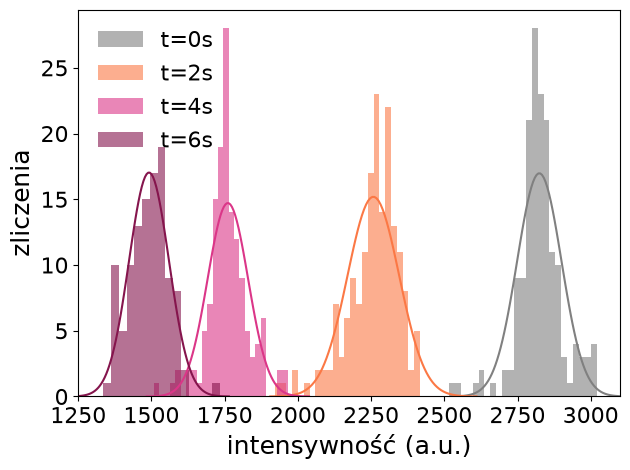

In [ ]:
#histogramy intensywności Raman E i A
szerokosc_binu_intensities_Raman_EA_0s = (np.max(intensities_Raman_EA_0s)-np.min(intensities_Raman_EA_0s))/25
liczba_probek_intensities_Raman_EA_0s = len(intensities_Raman_EA_0s)
y_intensities_Raman_EA_0s_ = y_intensities_Raman_EA_0s*liczba_probek_intensities_Raman_EA_0s*szerokosc_binu_intensities_Raman_EA_0s

szerokosc_binu_intensities_Raman_EA_2s = (np.max(intensities_Raman_EA_2s)-np.min(intensities_Raman_EA_2s))/25
liczba_probek_intensities_Raman_EA_2s = len(intensities_Raman_EA_2s)
y_intensities_Raman_EA_2s_ = y_intensities_Raman_EA_2s*liczba_probek_intensities_Raman_EA_2s*szerokosc_binu_intensities_Raman_EA_2s

szerokosc_binu_intensities_Raman_EA_4s = (np.max(intensities_Raman_EA_4s)-np.min(intensities_Raman_EA_4s))/25
liczba_probek_intensities_Raman_EA_4s = len(intensities_Raman_EA_4s)
y_intensities_Raman_EA_4s_ = y_intensities_Raman_EA_4s*liczba_probek_intensities_Raman_EA_4s*szerokosc_binu_intensities_Raman_EA_4s

szerokosc_binu_intensities_Raman_EA_6s = (np.max(intensities_Raman_EA_6s)-np.min(intensities_Raman_EA_6s))/15
liczba_probek_intensities_Raman_EA_6s = len(intensities_Raman_EA_6s)
y_intensities_Raman_EA_6s_ = y_intensities_Raman_EA_6s*liczba_probek_intensities_Raman_EA_6s*szerokosc_binu_intensities_Raman_EA_6s

plt.hist(intensities_Raman_EA_0s, bins=25, label="t=0s", alpha=0.6, color=colors[0])
plt.plot(x_intensities_Raman_EA_0s,y_intensities_Raman_EA_0s_,color=colors[0])

plt.hist(intensities_Raman_EA_2s, bins=25, label="t=2s", alpha=0.6,color=colors[1])
plt.plot(x_intensities_Raman_EA_2s,y_intensities_Raman_EA_2s_,color=colors[1])

plt.hist(intensities_Raman_EA_4s, bins=25, label="t=4s", alpha=0.6,color=colors[2])
plt.plot(x_intensities_Raman_EA_4s,y_intensities_Raman_EA_4s_,color=colors[2])

plt.hist(intensities_Raman_EA_6s, bins=15, label="t=6s", alpha=0.6,color=colors[3])
plt.plot(x_intensities_Raman_EA_6s,y_intensities_Raman_EA_6s_,color=colors[3])

plt.xlabel(r"intensywność (a.u.)")
plt.ylabel("zliczenia")
plt.legend()
plt.xlim(1250,3100)
plt.savefig(sciezka/'histogram_intensywnosci_Raman_EA.png')

In [ ]:
#średnie fwhm pików E i A na podstawie rozkładu normalnego
mu_fwhms_Raman_EA_0s, sigma_fwhms_Raman_EA_0s = norm.fit(fwhms_Raman_EA_0s)
print(f"{mu_fwhms_Raman_EA_0s} ± {sigma_fwhms_Raman_EA_0s}")
x_fwhms_Raman_EA_0s,y_fwhms_Raman_EA_0s=gauss(mu_fwhms_Raman_EA_0s,sigma_fwhms_Raman_EA_0s)

mu_fwhms_Raman_EA_2s, sigma_fwhms_Raman_EA_2s = norm.fit(fwhms_Raman_EA_2s)
print(f"{mu_fwhms_Raman_EA_2s} ± {sigma_fwhms_Raman_EA_2s}")
x_fwhms_Raman_EA_2s,y_fwhms_Raman_EA_2s=gauss(mu_fwhms_Raman_EA_2s,sigma_fwhms_Raman_EA_2s)

mu_fwhms_Raman_EA_4s, sigma_fwhms_Raman_EA_4s = norm.fit(fwhms_Raman_EA_4s)
print(f"{mu_fwhms_Raman_EA_4s} ± {sigma_fwhms_Raman_EA_4s}")
x_fwhms_Raman_EA_4s,y_fwhms_Raman_EA_4s=gauss(mu_fwhms_Raman_EA_4s,sigma_fwhms_Raman_EA_4s)

mu_fwhms_Raman_EA_6s, sigma_fwhms_Raman_EA_6s = norm.fit(fwhms_Raman_EA_6s)
print(f"{mu_fwhms_Raman_EA_6s} ± {sigma_fwhms_Raman_EA_6s}")
x_fwhms_Raman_EA_6s,y_fwhms_Raman_EA_6s=gauss(mu_fwhms_Raman_EA_6s,sigma_fwhms_Raman_EA_6s)

mu_fwhms_Raman_EA_8s, sigma_fwhms_Raman_EA_8s = norm.fit(fwhms_Raman_EA_8s)
print(f"{mu_fwhms_Raman_EA_8s} ± {sigma_fwhms_Raman_EA_8s}")

mu_fwhms_EA=[mu_fwhms_Raman_EA_0s,mu_fwhms_Raman_EA_2s,mu_fwhms_Raman_EA_4s,mu_fwhms_Raman_EA_6s,mu_fwhms_Raman_EA_8s]
u_fwhms_EA=[sigma_fwhms_Raman_EA_0s,sigma_fwhms_Raman_EA_2s,sigma_fwhms_Raman_EA_4s,sigma_fwhms_Raman_EA_6s,sigma_fwhms_Raman_EA_8s]

4.187507636022775 ± 0.09568003035900863
3.868571210332594 ± 0.12892654641219406
4.344086314949195 ± 0.09371372070414946
4.678884063236421 ± 0.0986259947325752
5.3254549210458295 ± 0.0


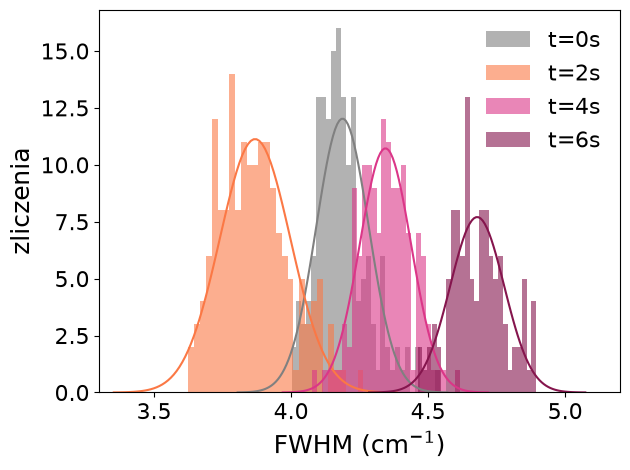

In [ ]:
#histogramy fwhm piku Raman E i A
szerokosc_binu_fwhms_Raman_EA_0s = (np.max(fwhms_Raman_EA_0s)-np.min(fwhms_Raman_EA_0s))/30
liczba_probek_fwhms_Raman_EA_0s = len(fwhms_Raman_EA_0s)
y_fwhms_Raman_EA_0s_ = y_fwhms_Raman_EA_0s*liczba_probek_fwhms_Raman_EA_0s*szerokosc_binu_fwhms_Raman_EA_0s

szerokosc_binu_fwhms_Raman_EA_2s = (np.max(fwhms_Raman_EA_2s)-np.min(fwhms_Raman_EA_2s))/30
liczba_probek_fwhms_Raman_EA_2s = len(fwhms_Raman_EA_2s)
y_fwhms_Raman_EA_2s_ = y_fwhms_Raman_EA_2s*liczba_probek_fwhms_Raman_EA_2s*szerokosc_binu_fwhms_Raman_EA_2s

szerokosc_binu_fwhms_Raman_EA_4s = (np.max(fwhms_Raman_EA_4s)-np.min(fwhms_Raman_EA_4s))/30
liczba_probek_fwhms_Raman_EA_4s = len(fwhms_Raman_EA_4s)
y_fwhms_Raman_EA_4s_ = y_fwhms_Raman_EA_4s*liczba_probek_fwhms_Raman_EA_4s*szerokosc_binu_fwhms_Raman_EA_4s

szerokosc_binu_fwhms_Raman_EA_6s = (np.max(fwhms_Raman_EA_6s)-np.min(fwhms_Raman_EA_6s))/25
liczba_probek_fwhms_Raman_EA_6s = len(fwhms_Raman_EA_6s)
y_fwhms_Raman_EA_6s_ = y_fwhms_Raman_EA_6s*liczba_probek_fwhms_Raman_EA_6s*szerokosc_binu_fwhms_Raman_EA_6s




plt.hist(fwhms_Raman_EA_0s, bins=30, label="t=0s", alpha=0.6, color=colors[0])
plt.plot(x_fwhms_Raman_EA_0s,y_fwhms_Raman_EA_0s_,color=colors[0])

plt.hist(fwhms_Raman_EA_2s, bins=30, label="t=2s", alpha=0.6,color=colors[1])
plt.plot(x_fwhms_Raman_EA_2s,y_fwhms_Raman_EA_2s_,color=colors[1])

plt.hist(fwhms_Raman_EA_4s, bins=30, label="t=4s", alpha=0.6,color=colors[2])
plt.plot(x_fwhms_Raman_EA_4s,y_fwhms_Raman_EA_4s_,color=colors[2])

plt.hist(fwhms_Raman_EA_6s, bins=25, label="t=6s", alpha=0.6,color=colors[3])
plt.plot(x_fwhms_Raman_EA_6s,y_fwhms_Raman_EA_6s_,color=colors[3])

plt.xlabel(r"FWHM (cm$^{-1}$)")
plt.ylabel("zliczenia")
plt.legend()
plt.xlim(3.3,5.2)
plt.savefig(sciezka/'histogram_fwhm_Raman_EA.png')

In [ ]:
#średnie pozycje pików 2LA(M) na podstawie rozkładu normalnego
mu_centers_Raman_LA_0s, sigma_centers_Raman_LA_0s = norm.fit(centers_Raman_LA_0s)
print(f"{mu_centers_Raman_LA_0s} ± {sigma_centers_Raman_LA_0s}")
x_centers_Raman_LA_0s,y_centers_Raman_LA_0s=gauss(mu_centers_Raman_LA_0s,sigma_centers_Raman_LA_0s)

mu_centers_Raman_LA_2s, sigma_centers_Raman_LA_2s = norm.fit(centers_Raman_LA_2s)
print(f"{mu_centers_Raman_LA_2s} ± {sigma_centers_Raman_LA_2s}")
x_centers_Raman_LA_2s,y_centers_Raman_LA_2s=gauss(mu_centers_Raman_LA_2s,sigma_centers_Raman_LA_2s)

mu_centers_Raman_LA_4s, sigma_centers_Raman_LA_4s = norm.fit(centers_Raman_LA_4s)
print(f"{mu_centers_Raman_LA_4s} ± {sigma_centers_Raman_LA_4s}")
x_centers_Raman_LA_4s,y_centers_Raman_LA_4s=gauss(mu_centers_Raman_LA_4s,sigma_centers_Raman_LA_4s)


mu_centers_Raman_LA_6s, sigma_centers_Raman_LA_6s = norm.fit(centers_Raman_LA_6s)
print(f"{mu_centers_Raman_LA_6s} ± {sigma_centers_Raman_LA_6s}")
x_centers_Raman_LA_6s,y_centers_Raman_LA_6s=gauss(mu_centers_Raman_LA_6s,sigma_centers_Raman_LA_6s)

mu_centers_Raman_LA_8s, sigma_centers_Raman_LA_8s = norm.fit(centers_Raman_LA_8s)
print(f"{mu_centers_Raman_LA_8s} ± {sigma_centers_Raman_LA_8s}")

mu_centers_LA=[mu_centers_Raman_LA_0s,mu_centers_Raman_LA_2s,mu_centers_Raman_LA_4s,mu_centers_Raman_LA_6s,mu_centers_Raman_LA_8s]
u_centers_LA=[sigma_centers_Raman_LA_0s,sigma_centers_Raman_LA_2s,sigma_centers_Raman_LA_4s,sigma_centers_Raman_LA_6s,sigma_centers_Raman_LA_8s]

258.88447458923076 ± 0.2618459545655528
260.3569348380276 ± 0.33464582669478676
259.97877107329043 ± 0.3452342147962189
259.81352699530305 ± 0.4140705365407402
258.84487311173905 ± 0.0


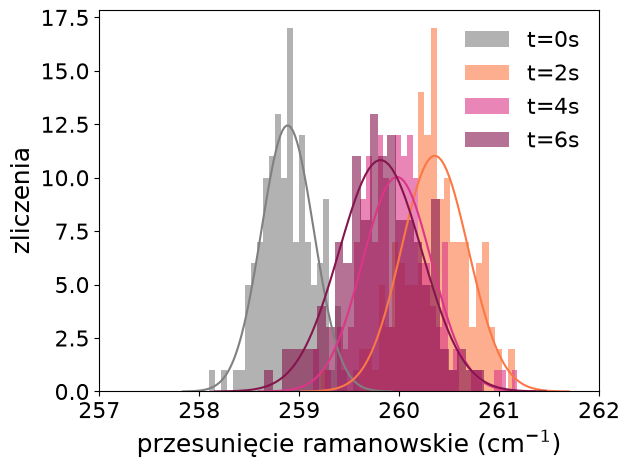

In [ ]:
#histogramy pozycji piku Raman 2LA(M)
szerokosc_binu_centers_Raman_LA_0s = (np.max(centers_Raman_LA_0s)-np.min(centers_Raman_LA_0s))/25
liczba_probek_centers_Raman_LA_0s = len(centers_Raman_LA_0s)
y_centers_Raman_LA_0s_ = y_centers_Raman_LA_0s*liczba_probek_centers_Raman_LA_0s*szerokosc_binu_centers_Raman_LA_0s

szerokosc_binu_centers_Raman_LA_2s = (np.max(centers_Raman_LA_2s)-np.min(centers_Raman_LA_2s))/30
liczba_probek_centers_Raman_LA_2s = len(centers_Raman_LA_2s)
y_centers_Raman_LA_2s_ = y_centers_Raman_LA_2s*liczba_probek_centers_Raman_LA_2s*szerokosc_binu_centers_Raman_LA_2s


szerokosc_binu_centers_Raman_LA_4s = (np.max(centers_Raman_LA_4s)-np.min(centers_Raman_LA_4s))/35
liczba_probek_centers_Raman_LA_4s = len(centers_Raman_LA_4s)
y_centers_Raman_LA_4s_ = y_centers_Raman_LA_4s*liczba_probek_centers_Raman_LA_4s*szerokosc_binu_centers_Raman_LA_4s

szerokosc_binu_centers_Raman_LA_6s = (np.max(centers_Raman_LA_6s)-np.min(centers_Raman_LA_6s))/25
liczba_probek_centers_Raman_LA_6s = len(centers_Raman_LA_6s)
y_centers_Raman_LA_6s_ = y_centers_Raman_LA_6s*liczba_probek_centers_Raman_LA_6s*szerokosc_binu_centers_Raman_LA_6s

plt.hist(centers_Raman_LA_0s, bins=25, label="t=0s", alpha=0.6, color=colors[0])
plt.plot(x_centers_Raman_LA_0s,y_centers_Raman_LA_0s_,color=colors[0])

plt.hist(centers_Raman_LA_2s, bins=30, label="t=2s", alpha=0.6,color=colors[1])
plt.plot(x_centers_Raman_LA_2s,y_centers_Raman_LA_2s_,color=colors[1])

plt.hist(centers_Raman_LA_4s, bins=35, label="t=4s", alpha=0.6,color=colors[2])
plt.plot(x_centers_Raman_LA_4s,y_centers_Raman_LA_4s_,color=colors[2])

plt.hist(centers_Raman_LA_6s, bins=25, label="t=6s", alpha=0.6,color=colors[3])
plt.plot(x_centers_Raman_LA_6s,y_centers_Raman_LA_6s_,color=colors[3])

plt.xlabel(r"przesunięcie ramanowskie (cm$^{-1}$)")
plt.ylabel("zliczenia")
plt.legend()
plt.xlim(257,262)
plt.savefig(sciezka/'histogram_pozycji_Raman_LA.png')

In [ ]:
#średnie intensywności pików 2LA(M) na podstawie rozkładu normalnego
mu_intensities_Raman_LA_0s, sigma_intensities_Raman_LA_0s = norm.fit(intensities_Raman_LA_0s)
print(f"{mu_intensities_Raman_LA_0s} ± {sigma_intensities_Raman_LA_0s}")
x_intensities_Raman_LA_0s,y_intensities_Raman_LA_0s=gauss(mu_intensities_Raman_LA_0s,sigma_intensities_Raman_LA_0s)

mu_intensities_Raman_LA_2s, sigma_intensities_Raman_LA_2s = norm.fit(intensities_Raman_LA_2s)
print(f"{mu_intensities_Raman_LA_2s} ± {sigma_intensities_Raman_LA_2s}")
x_intensities_Raman_LA_2s,y_intensities_Raman_LA_2s=gauss(mu_intensities_Raman_LA_2s,sigma_intensities_Raman_LA_2s)

mu_intensities_Raman_LA_4s, sigma_intensities_Raman_LA_4s = norm.fit(intensities_Raman_LA_4s)
print(f"{mu_intensities_Raman_LA_4s} ± {sigma_intensities_Raman_LA_4s}")
x_intensities_Raman_LA_4s,y_intensities_Raman_LA_4s=gauss(mu_intensities_Raman_LA_4s,sigma_intensities_Raman_LA_4s)


mu_intensities_Raman_LA_6s, sigma_intensities_Raman_LA_6s = norm.fit(intensities_Raman_LA_6s)
print(f"{mu_intensities_Raman_LA_6s} ± {sigma_intensities_Raman_LA_6s}")
x_intensities_Raman_LA_6s,y_intensities_Raman_LA_6s=gauss(mu_intensities_Raman_LA_6s,sigma_intensities_Raman_LA_6s)

mu_intensities_Raman_LA_8s, sigma_intensities_Raman_LA_8s = norm.fit(intensities_Raman_LA_8s)
print(f"{mu_intensities_Raman_LA_8s} ± {sigma_intensities_Raman_LA_8s}")

mu_intensities_LA=[mu_intensities_Raman_LA_0s,mu_intensities_Raman_LA_2s,mu_intensities_Raman_LA_4s,mu_intensities_Raman_LA_6s,mu_intensities_Raman_LA_8s]
u_intensities_LA=[sigma_intensities_Raman_LA_0s,sigma_intensities_Raman_LA_2s,sigma_intensities_Raman_LA_4s,sigma_intensities_Raman_LA_6s,sigma_intensities_Raman_LA_8s]

392.75664727513436 ± 14.285397267750838
287.804248304131 ± 12.666340189262467
243.47140895348247 ± 12.546226268330813
223.6624450398451 ± 11.065609583601615
173.14648129082894 ± 0.0


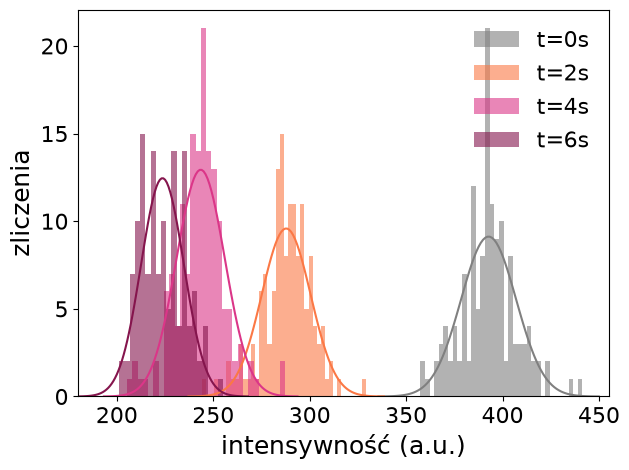

In [ ]:
#histogramy intensywności Raman 2LA(M)
szerokosc_binu_intensities_Raman_LA_0s=(np.max(intensities_Raman_LA_0s)-np.min(intensities_Raman_LA_0s))/35
liczba_probek_intensities_Raman_LA_0s=len(intensities_Raman_LA_0s)
y_intensities_Raman_LA_0s_=y_intensities_Raman_LA_0s*liczba_probek_intensities_Raman_LA_0s*szerokosc_binu_intensities_Raman_LA_0s

szerokosc_binu_intensities_Raman_LA_2s=(np.max(intensities_Raman_LA_2s)-np.min(intensities_Raman_LA_2s))/40
liczba_probek_intensities_Raman_LA_2s=len(intensities_Raman_LA_2s)
y_intensities_Raman_LA_2s_=y_intensities_Raman_LA_2s*liczba_probek_intensities_Raman_LA_2s*szerokosc_binu_intensities_Raman_LA_2s


szerokosc_binu_intensities_Raman_LA_4s=(np.max(intensities_Raman_LA_4s)-np.min(intensities_Raman_LA_4s))/30
liczba_probek_intensities_Raman_LA_4s=len(intensities_Raman_LA_4s)
y_intensities_Raman_LA_4s_=y_intensities_Raman_LA_4s*liczba_probek_intensities_Raman_LA_4s*szerokosc_binu_intensities_Raman_LA_4s

szerokosc_binu_intensities_Raman_LA_6s=(np.max(intensities_Raman_LA_6s)-np.min(intensities_Raman_LA_6s))/20
liczba_probek_intensities_Raman_LA_6s=len(intensities_Raman_LA_6s)
y_intensities_Raman_LA_6s_=y_intensities_Raman_LA_6s*liczba_probek_intensities_Raman_LA_6s*szerokosc_binu_intensities_Raman_LA_6s


plt.hist(intensities_Raman_LA_0s, bins=35, label="t=0s", alpha=0.6, color=colors[0])
plt.plot(x_intensities_Raman_LA_0s,y_intensities_Raman_LA_0s_,color=colors[0])

plt.hist(intensities_Raman_LA_2s, bins=40, label="t=2s", alpha=0.6,color=colors[1])
plt.plot(x_intensities_Raman_LA_2s,y_intensities_Raman_LA_2s_,color=colors[1])

plt.hist(intensities_Raman_LA_4s, bins=30, label="t=4s", alpha=0.6,color=colors[2])
plt.plot(x_intensities_Raman_LA_4s,y_intensities_Raman_LA_4s_,color=colors[2])

plt.hist(intensities_Raman_LA_6s, bins=20, label="t=6s", alpha=0.6,color=colors[3])
plt.plot(x_intensities_Raman_LA_6s,y_intensities_Raman_LA_6s_,color=colors[3])

plt.xlabel(r"intensywność (a.u.)")
plt.ylabel("zliczenia")
plt.legend()
plt.xlim(180,455)
plt.savefig(sciezka/'histogram_intensywnosci_Raman_LA.png')

In [ ]:
#średnie fwhm pików 2LA(M) na podstawie rozkładu normalnego
mu_fwhms_Raman_LA_0s, sigma_fwhms_Raman_LA_0s = norm.fit(fwhms_Raman_LA_0s)
print(f"{mu_fwhms_Raman_LA_0s} ± {sigma_fwhms_Raman_LA_0s}")
x_fwhms_Raman_LA_0s,y_fwhms_Raman_LA_0s=gauss(mu_fwhms_Raman_LA_0s,sigma_fwhms_Raman_LA_0s)

mu_fwhms_Raman_LA_2s, sigma_fwhms_Raman_LA_2s = norm.fit(fwhms_Raman_LA_2s)
print(f"{mu_fwhms_Raman_LA_2s} ± {sigma_fwhms_Raman_LA_2s}")
x_fwhms_Raman_LA_2s,y_fwhms_Raman_LA_2s=gauss(mu_fwhms_Raman_LA_2s,sigma_fwhms_Raman_LA_2s)

mu_fwhms_Raman_LA_4s, sigma_fwhms_Raman_LA_4s = norm.fit(fwhms_Raman_LA_4s)
print(f"{mu_fwhms_Raman_LA_4s} ± {sigma_fwhms_Raman_LA_4s}")
x_fwhms_Raman_LA_4s,y_fwhms_Raman_LA_4s=gauss(mu_fwhms_Raman_LA_4s,sigma_fwhms_Raman_LA_4s)


mu_fwhms_Raman_LA_6s, sigma_fwhms_Raman_LA_6s = norm.fit(fwhms_Raman_LA_6s)
print(f"{mu_fwhms_Raman_LA_6s} ± {sigma_fwhms_Raman_LA_6s}")
x_fwhms_Raman_LA_6s,y_fwhms_Raman_LA_6s=gauss(mu_fwhms_Raman_LA_6s,sigma_fwhms_Raman_LA_6s)

mu_fwhms_Raman_LA_8s, sigma_fwhms_Raman_LA_8s = norm.fit(fwhms_Raman_LA_8s)
print(f"{mu_fwhms_Raman_LA_8s} ± {sigma_fwhms_Raman_LA_8s}")

mu_fwhms_LA=[mu_fwhms_Raman_LA_0s,mu_fwhms_Raman_LA_2s,mu_fwhms_Raman_LA_4s,mu_fwhms_Raman_LA_6s,mu_fwhms_Raman_LA_8s]
u_fwhms_LA=[sigma_fwhms_Raman_LA_0s,sigma_fwhms_Raman_LA_2s,sigma_fwhms_Raman_LA_4s,sigma_fwhms_Raman_LA_6s,sigma_fwhms_Raman_LA_8s]

11.14843430413492 ± 0.8732865603154811
15.022099208465473 ± 1.9202577546563846
15.080816948552718 ± 2.2603445155277133
15.578395145664597 ± 2.6420595523672867
17.553372910533067 ± 0.0


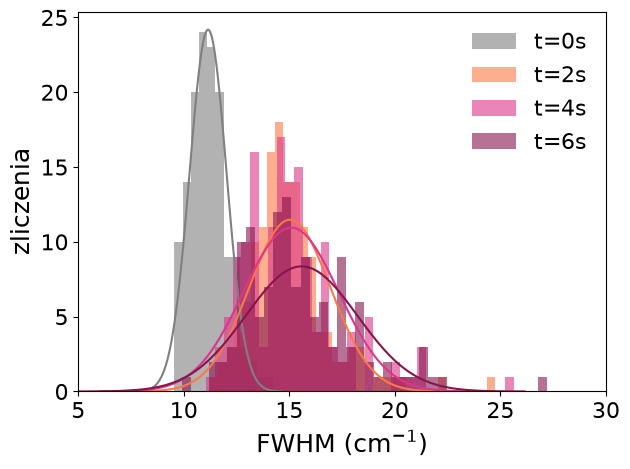

In [ ]:
#histogramy fwhm piku Raman 2LA(M)
szerokosc_binu_fwhms_Raman_LA_0s=(np.max(fwhms_Raman_LA_0s)-np.min(fwhms_Raman_LA_0s))/12
liczba_probek_fwhms_Raman_LA_0s=len(fwhms_Raman_LA_0s)
y_fwhms_Raman_LA_0s_=y_fwhms_Raman_LA_0s*liczba_probek_fwhms_Raman_LA_0s*szerokosc_binu_fwhms_Raman_LA_0s

szerokosc_binu_fwhms_Raman_LA_2s=(np.max(fwhms_Raman_LA_2s)-np.min(fwhms_Raman_LA_2s))/35
liczba_probek_fwhms_Raman_LA_2s=len(fwhms_Raman_LA_2s)
y_fwhms_Raman_LA_2s_=y_fwhms_Raman_LA_2s*liczba_probek_fwhms_Raman_LA_2s*szerokosc_binu_fwhms_Raman_LA_2s

szerokosc_binu_fwhms_Raman_LA_4s=(np.max(fwhms_Raman_LA_4s)-np.min(fwhms_Raman_LA_4s))/35
liczba_probek_fwhms_Raman_LA_4s=len(fwhms_Raman_LA_4s)
y_fwhms_Raman_LA_4s_=y_fwhms_Raman_LA_4s*liczba_probek_fwhms_Raman_LA_4s*szerokosc_binu_fwhms_Raman_LA_4s

szerokosc_binu_fwhms_Raman_LA_6s=(np.max(fwhms_Raman_LA_6s)-np.min(fwhms_Raman_LA_6s))/40
liczba_probek_fwhms_Raman_LA_6s=len(fwhms_Raman_LA_6s)
y_fwhms_Raman_LA_6s_=y_fwhms_Raman_LA_6s*liczba_probek_fwhms_Raman_LA_6s*szerokosc_binu_fwhms_Raman_LA_6s

plt.hist(fwhms_Raman_LA_0s, bins=12, label="t=0s", alpha=0.6, color=colors[0])
plt.plot(x_fwhms_Raman_LA_0s,y_fwhms_Raman_LA_0s_,color=colors[0])

plt.hist(fwhms_Raman_LA_2s, bins=35, label="t=2s", alpha=0.6,color=colors[1])
plt.plot(x_fwhms_Raman_LA_2s,y_fwhms_Raman_LA_2s_,color=colors[1])

plt.hist(fwhms_Raman_LA_4s, bins=35, label="t=4s", alpha=0.6,color=colors[2])
plt.plot(x_fwhms_Raman_LA_4s,y_fwhms_Raman_LA_4s_,color=colors[2])

plt.hist(fwhms_Raman_LA_6s, bins=40, label="t=6s", alpha=0.6,color=colors[3])
plt.plot(x_fwhms_Raman_LA_6s,y_fwhms_Raman_LA_6s_,color=colors[3])
plt.xlabel(r"FWHM (cm$^{-1}$)")
plt.ylabel("zliczenia")
plt.legend()
plt.xlim(5,30)
plt.savefig(sciezka/'histogram_fwhm_Raman_LA.png')

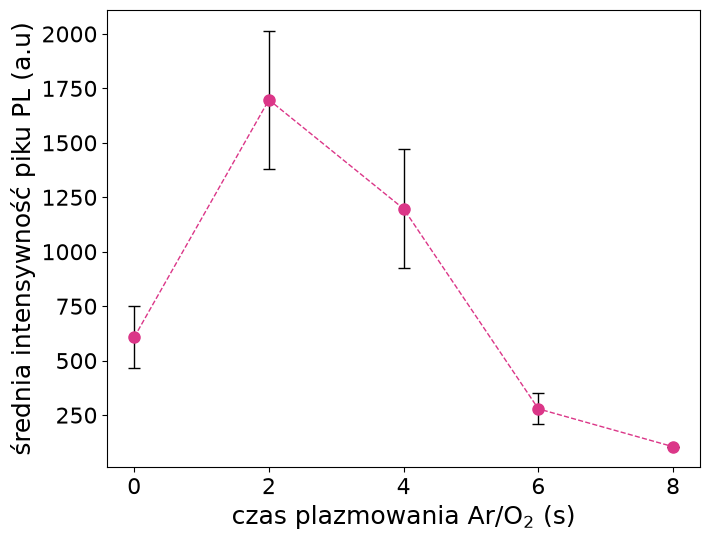

In [ ]:
#wstępne zależności
ustaw_styl_wykresow()
time=[0,2,4,6,8]
plt.figure(figsize=(7.2, 5.5))
plt.errorbar(time,mu_intensities_PL,yerr=u_intensities_PL,fmt="o--",color=colors[2],ecolor="black",capsize=4,capthick=1,linewidth=1,markersize=8,label="Próbka 1",)
plt.xlabel(r"czas plazmowania Ar/O$_2$ (s)")
plt.ylabel("średnia intensywność piku PL (a.u)")
plt.savefig(sciezka/'zaleznosc_I_PL_od_t.png')

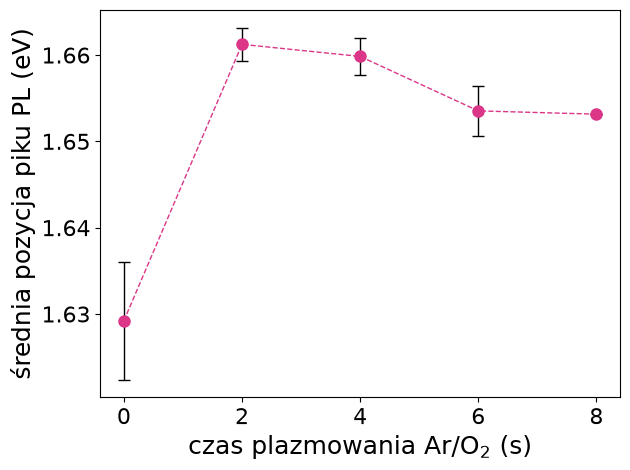

In [ ]:
time=[0,2,4,6,8]
plt.errorbar(time,mu_centers_PL,yerr=u_centers_PL,fmt="o--",color=colors[2],ecolor="black",capsize=4,capthick=1,linewidth=1,markersize=8,label="Próbka 1",)
plt.xlabel(r"czas plazmowania Ar/O$_2$ (s)")
plt.ylabel("średnia pozycja piku PL (eV)")
plt.savefig(sciezka/'zaleznosc_x_PL_od_t.png')

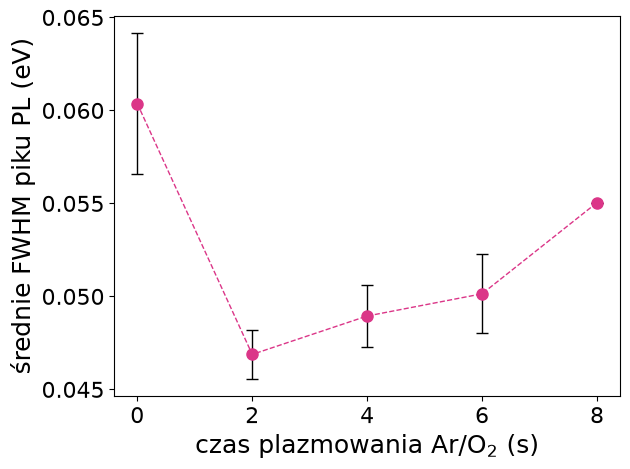

In [ ]:
time=[0,2,4,6,8]
plt.errorbar(time,mu_fwhms_PL,yerr=u_fwhms_PL,fmt="o--",color=colors[2],ecolor="black",capsize=4,capthick=1,linewidth=1,markersize=8,label="Próbka 1",)

plt.xlabel(r"czas plazmowania Ar/O$_2$ (s)")
plt.ylabel("średnie FWHM piku PL (eV)")
plt.savefig(sciezka/'zaleznosc_FWHM_PL_od_t.png')

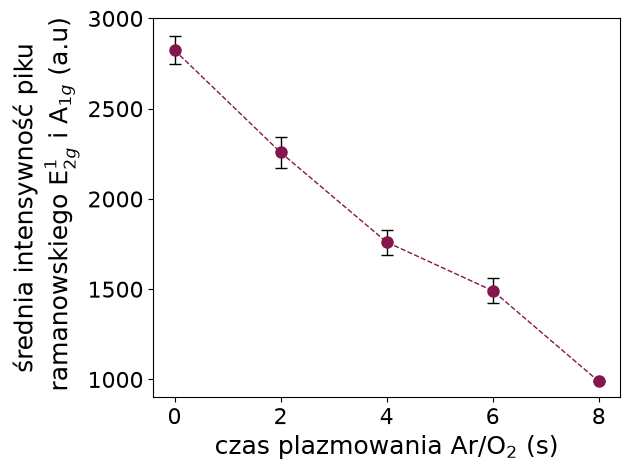

In [ ]:
time=[0,2,4,6,8]
plt.errorbar(time,mu_intensities_EA,yerr=u_intensities_EA,fmt="o--",color=colors[3],ecolor="black",capsize=4,capthick=1,linewidth=1,markersize=8,label="pik E$^1_{2g}$ i pik A$_{1g}$")
plt.xlabel(r"czas plazmowania Ar/O$_2$ (s)")
plt.ylabel("średnia intensywność piku\n ramanowskiego E$^1_{2g}$ i A$_{1g}$ (a.u)")
plt.ylim(900,3000)
plt.savefig(sciezka/'zaleznosc_I_Raman_EA_od_t.png')

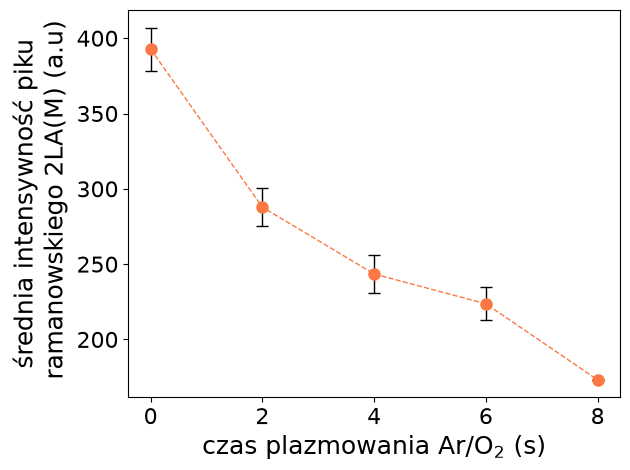

In [ ]:
time=[0,2,4,6,8]
plt.errorbar(time,mu_intensities_LA,yerr=u_intensities_LA,fmt="o--",color=colors[1],ecolor="black",capsize=4,capthick=1,linewidth=1,markersize=8,label="pik 2LA(M)")

plt.xlabel(r"czas plazmowania Ar/O$_2$ (s)")
plt.ylabel("średnia intensywność piku\n ramanowskiego 2LA(M) (a.u)")

plt.savefig(sciezka/'zaleznosc_I_Raman_LA_od_t.png')

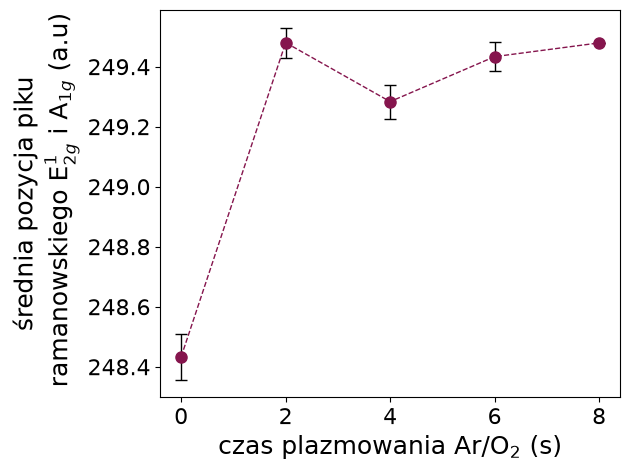

In [ ]:
time=[0,2,4,6,8]
plt.errorbar(time,mu_centers_EA,yerr=u_centers_EA,fmt="o--",color=colors[3],ecolor="black",capsize=4,capthick=1,linewidth=1,markersize=8,label="pik E$^1_{2g}$ i pik A$_{1g}$")
#plt.errorbar(time,mu_centers_LA,yerr=u_centers_LA,fmt="o--",color=colors[1],ecolor="black",capsize=4,capthick=1,linewidth=1,markersize=8,label="pik 2LA(M)")
plt.xlabel(r"czas plazmowania Ar/O$_2$ (s)")
plt.ylabel("średnia pozycja piku\n ramanowskiego E$^1_{2g}$ i A$_{1g}$ (a.u)")
plt.savefig(sciezka/'zaleznosc_x_Raman_EA_od_t.png')

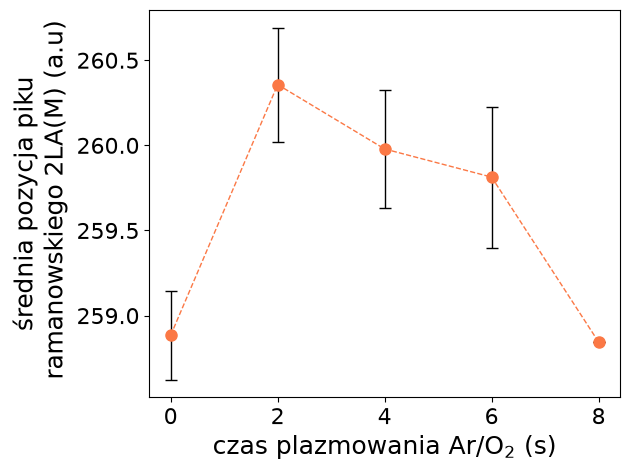

In [ ]:
time=[0,2,4,6,8]
plt.errorbar(time,mu_centers_LA,yerr=u_centers_LA,fmt="o--",color=colors[1],ecolor="black",capsize=4,capthick=1,linewidth=1,markersize=8,label="pik 2LA(M)")
plt.xlabel(r"czas plazmowania Ar/O$_2$ (s)")
plt.ylabel("średnia pozycja piku\n ramanowskiego 2LA(M) (a.u)")
plt.savefig(sciezka/'zaleznosc_x_Raman_LA_od_t.png')

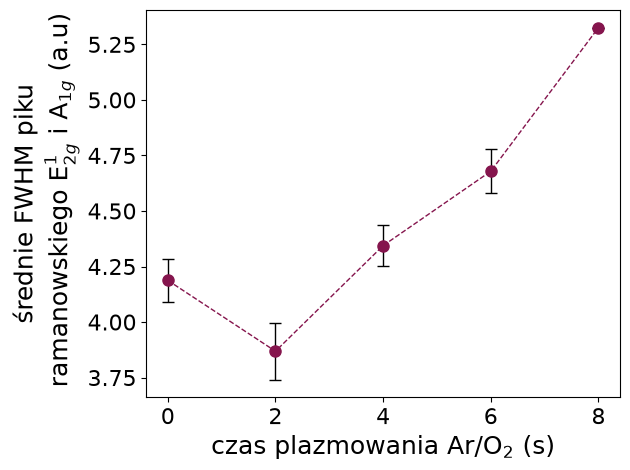

In [ ]:
time=[0,2,4,6,8]
plt.errorbar(time,mu_fwhms_EA,yerr=u_fwhms_EA,fmt="o--",color=colors[3],ecolor="black",capsize=4,capthick=1,linewidth=1,markersize=8,label="pik E$^1_{2g}$ i pik A$_{1g}$")
#plt.errorbar(time,mu_fwhms_LA,yerr=u_fwhms_LA,fmt="o--",color=colors[1],ecolor="black",capsize=4,capthick=1,linewidth=1,markersize=8,label="pik 2LA(M)")

plt.xlabel(r"czas plazmowania Ar/O$_2$ (s)")
plt.ylabel("średnie FWHM piku\n ramanowskiego E$^1_{2g}$ i A$_{1g}$ (a.u)")
plt.savefig(sciezka/'zaleznosc_fwhm_Raman_EA_od_t.png')

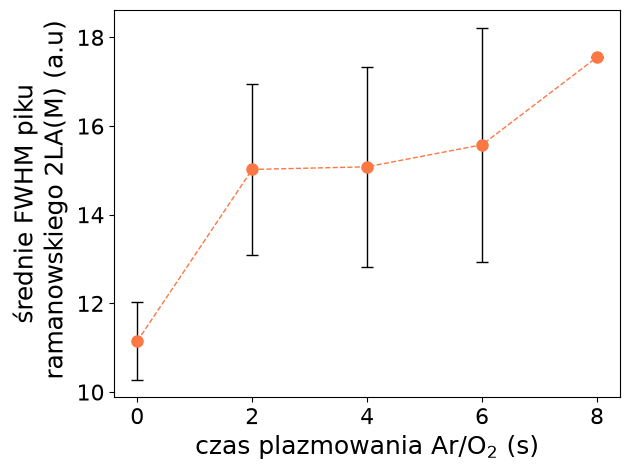

In [ ]:
time=[0,2,4,6,8]
plt.errorbar(time,mu_fwhms_LA,yerr=u_fwhms_LA,fmt="o--",color=colors[1],ecolor="black",capsize=4,capthick=1,linewidth=1,markersize=8,label="pik 2LA(M)")

plt.xlabel(r"czas plazmowania Ar/O$_2$ (s)")
plt.ylabel("średnie FWHM piku\n ramanowskiego 2LA(M) (a.u)")
plt.savefig(sciezka/'zaleznosc_fwhm_Raman_LA_od_t.png')

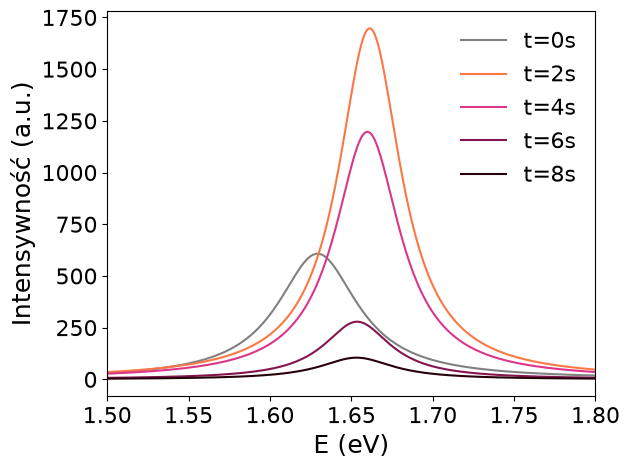

In [ ]:
#piki PL na podstawie uśrednionych x, I i fwhm
x = np.linspace(1.45, 1.85, 500)
times = [0, 2, 4, 6, 8]

for t, c, f, h, col in zip(times, mu_centers_PL, mu_fwhms_PL, mu_intensities_PL, colors):
    y = lorentz(x, h, c, f)
    plt.plot(x, y, label=f"t={t}s", color=col)

plt.xlabel("E (eV)")
plt.ylabel("Intensywność (a.u.)")
plt.xlim(1.5, 1.8)
plt.legend()
plt.savefig(sciezka/'usrednione_PL.png')

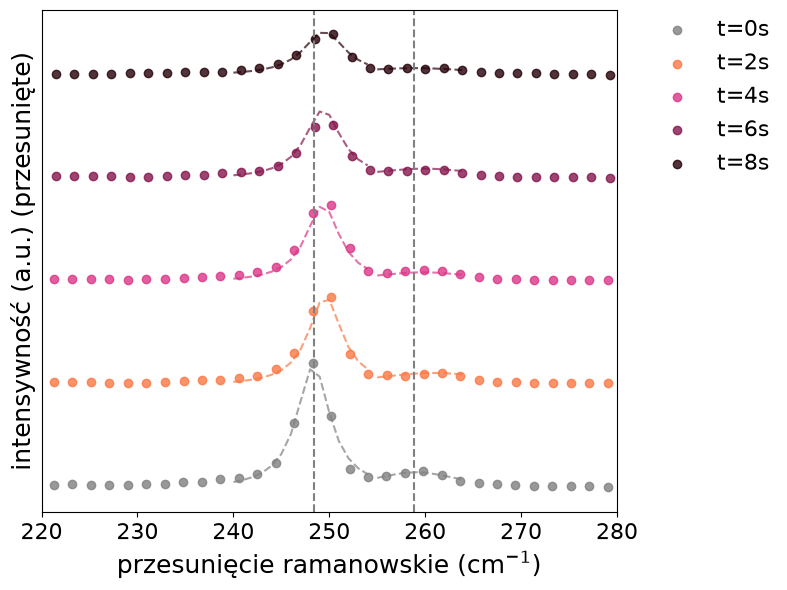

In [ ]:


x_data = [rs_Raman_0s[123], rs_Raman_2s[123], rs_Raman_4s[123], rs_Raman_6s[123], rs_Raman_8s]
y_data = [I_Raman_0s[123], I_Raman_2s[123], I_Raman_4s[123], I_Raman_6s[123], I_Raman_8s]

x_EA = np.arange(240, 255)
x_LA = np.arange(255, 265)

centers_EA = [centers_Raman_EA_0s[0], centers_Raman_EA_2s[0], centers_Raman_EA_4s[0], centers_Raman_EA_6s[0], centers_Raman_EA_8s]
fwhms_EA = [fwhms_Raman_EA_0s[0], fwhms_Raman_EA_2s[0], fwhms_Raman_EA_4s[0], fwhms_Raman_EA_6s[0], fwhms_Raman_EA_8s]
intensities_EA = [intensities_Raman_EA_0s[0], intensities_Raman_EA_2s[0], intensities_Raman_EA_4s[0], intensities_Raman_EA_6s[0], intensities_Raman_EA_8s]

centers_LA = [centers_Raman_LA_0s[0], centers_Raman_LA_2s[0], centers_Raman_LA_4s[0], centers_Raman_LA_6s[0], centers_Raman_LA_8s]
fwhms_LA = [fwhms_Raman_LA_0s[0], fwhms_Raman_LA_2s[0], fwhms_Raman_LA_4s[0], fwhms_Raman_LA_6s[0], fwhms_Raman_LA_8s]
intensities_LA = [intensities_Raman_LA_0s[0], intensities_Raman_LA_2s[0], intensities_Raman_LA_4s[0], intensities_Raman_LA_6s[0], intensities_Raman_LA_8s]

labels = ["t=0s", "t=2s", "t=4s", "t=6s", "t=8s"]
y_offset_step = 2300
x_offset_step = 0
legend_handles = []

plt.figure(figsize=(8, 6))


# Pętla generująca wykres kaskadowy
for i, (x, y, label, color) in enumerate(zip(x_data, y_data, labels, colors)):
    x_shifted = x + (i * x_offset_step)
    y_shifted = y + (i * y_offset_step)

    # Rysowanie głównego widma jako linia ciągła (zamiast scatter)
    plt.scatter(x_shifted, y_shifted, color=color, label=label, alpha=0.8)

    # Obliczanie i rysowanie dopasowań Lorentza
    y_EA = lorentz(x_EA, intensities_EA[i], centers_EA[i], fwhms_EA[i])
    y_LA = lorentz(x_LA, intensities_LA[i], centers_LA[i], fwhms_LA[i])
    
    plt.plot(x_EA, y_EA + (i * y_offset_step), color=color, linestyle='--', alpha=0.7)
    plt.plot(x_LA, y_LA + (i * y_offset_step), color=color, linestyle='--', alpha=0.7)

    handle = mlines.Line2D([], [], color=color, marker='o', linestyle='--', 
                              markersize=6, label=label)
    legend_handles.append(handle)

# Formatowanie osi i opisów
plt.yticks([], []) # ukrycie wartości na osi y
plt.xlabel(r"przesunięcie ramanowskie (cm$^{-1}$)")
plt.ylabel("intensywność (a.u.) (przesunięte)")

# Linie odniesienia dla średnich pozycji
plt.axvline(mu_centers_EA[0], color='gray', linestyle="--")
plt.axvline(mu_centers_LA[0], color='gray', linestyle="--")

    
plt.legend(handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.1, frameon=False)
plt.xlim(220,280)
plt.tight_layout()

# Zapis do pliku
plt.savefig(sciezka / 'Raman_pojedyncze_widma.png', dpi=300)
plt.show()